In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from medmnist import PathMNIST, INFO
import time


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


In [3]:
info = INFO["pathmnist"]
num_classes = len(info["label"])

transform = transforms.Compose([
    transforms.Resize((64, 64)),  # CNNs expect 224×224
    transforms.ToTensor()
])

train_ds = PathMNIST(split="train", transform=transform, download=True)
val_ds   = PathMNIST(split="val",   transform=transform, download=True)
test_ds  = PathMNIST(split="test",  transform=transform, download=True)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False)

print(len(train_ds), len(val_ds), len(test_ds))


Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
89996 10004 7180


In [4]:
resnet = models.resnet18(pretrained=True)

for p in resnet.parameters():
    p.requires_grad = False

in_features = resnet.fc.in_features
resnet.fc = nn.Identity()

resnet = resnet.to(device)
resnet.eval()


D:\python\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\python\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [5]:
linear_probe = nn.Linear(in_features, num_classes).to(device)


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)


In [7]:
def run_epoch(backbone, head, loader, train=False):
    head.train() if train else head.eval()
    backbone.eval()

    total_loss, correct, total = 0, 0, 0

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.squeeze().long().to(device)

            feats = backbone(x)
            outputs = head(feats)
            loss = criterion(outputs, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct += (outputs.argmax(1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, 100 * correct / total


In [11]:
import time
import matplotlib.pyplot as plt

epochs = 10
start = time.time()

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for e in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(resnet, linear_probe, train_loader, train=True)
    va_loss, va_acc = run_epoch(resnet, linear_probe, val_loader)

    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accs.append(tr_acc)
    val_accs.append(va_acc)

    print(
        f"Epoch {e:02d} | "
        f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f} | Val Acc: {va_acc:.2f}%"
    )

print("Training time:", time.time() - start)

Epoch 01 | Train Loss: 0.4839 | Train Acc: 82.57% | Val Loss: 0.5025 | Val Acc: 81.95%
Epoch 02 | Train Loss: 0.4830 | Train Acc: 82.71% | Val Loss: 0.5135 | Val Acc: 81.68%
Epoch 03 | Train Loss: 0.4830 | Train Acc: 82.65% | Val Loss: 0.5035 | Val Acc: 81.87%
Epoch 04 | Train Loss: 0.4820 | Train Acc: 82.63% | Val Loss: 0.5036 | Val Acc: 81.98%
Epoch 05 | Train Loss: 0.4825 | Train Acc: 82.69% | Val Loss: 0.5011 | Val Acc: 82.00%
Epoch 06 | Train Loss: 0.4820 | Train Acc: 82.72% | Val Loss: 0.5097 | Val Acc: 81.79%
Epoch 07 | Train Loss: 0.4815 | Train Acc: 82.72% | Val Loss: 0.5113 | Val Acc: 81.76%
Epoch 08 | Train Loss: 0.4812 | Train Acc: 82.77% | Val Loss: 0.5061 | Val Acc: 81.86%
Epoch 09 | Train Loss: 0.4815 | Train Acc: 82.74% | Val Loss: 0.5100 | Val Acc: 81.85%
Epoch 10 | Train Loss: 0.4808 | Train Acc: 82.68% | Val Loss: 0.5085 | Val Acc: 82.07%
Training time: 597.4215471744537


In [12]:
test_loss, test_acc = run_epoch(resnet, linear_probe, test_loader)

print("\n==== ResNet-50 TEST RESULT ====")
print(f"Test Accuracy: {test_acc:.2f}%")



==== ResNet-50 TEST RESULT ====
Test Accuracy: 80.39%


In [13]:
resnet.eval()
linear_probe.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.squeeze().long()

        feats = resnet(x)
        outputs = linear_probe(feats)
        preds = outputs.argmax(dim=1).cpu()

        all_preds.append(preds)
        all_labels.append(y)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

print("Total test samples:", len(y_true))


Total test samples: 7180


In [14]:
classwise_acc = {}

for cls in range(num_classes):
    mask = (y_true == cls)
    correct = (y_pred[mask] == cls).sum()
    total = mask.sum()

    acc = correct / total if total > 0 else 0
    classwise_acc[cls] = acc

for cls, acc in classwise_acc.items():
    print(f"Class {cls} accuracy: {acc:.4f}")


Class 0 accuracy: 0.9694
Class 1 accuracy: 0.9894
Class 2 accuracy: 0.7227
Class 3 accuracy: 0.9069
Class 4 accuracy: 0.7536
Class 5 accuracy: 0.5878
Class 6 accuracy: 0.8151
Class 7 accuracy: 0.4798
Class 8 accuracy: 0.7161


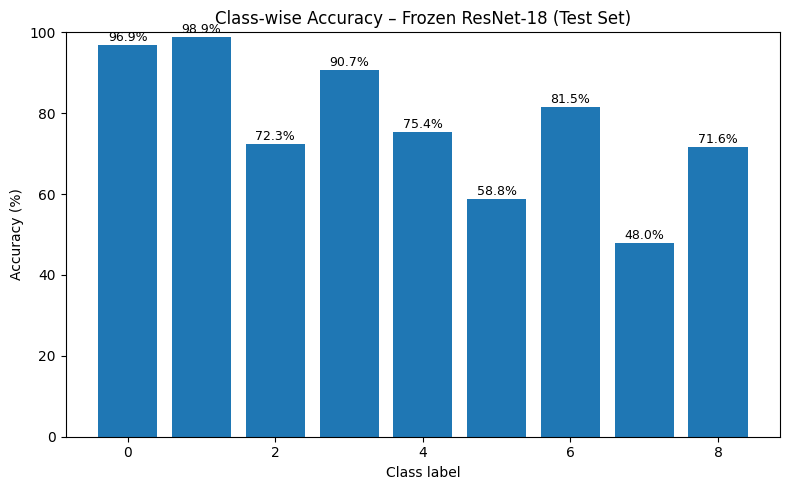

In [15]:
import matplotlib.pyplot as plt

classes = list(classwise_acc.keys())
accuracies = [classwise_acc[c] * 100 for c in classes]

plt.figure(figsize=(8,5))
plt.bar(classes, accuracies)
plt.xlabel("Class label")
plt.ylabel("Accuracy (%)")
plt.title("Class-wise Accuracy – Frozen ResNet-18 (Test Set)")
plt.ylim(0, 100)

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f"{acc:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()


In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)


Confusion Matrix:
 [[1297    8    2    0   18   10    2    0    1]
 [   1  838    1    0    4    3    0    0    0]
 [   0    0  245    0    0   45    0   46    3]
 [   1    0   28  575    1    0    8    7   14]
 [  48   47   18    6  780   17   22   76   21]
 [   0    3   35    0    7  348    1  162   36]
 [   4    1   18   12   29    3  604    2   68]
 [   0    2   56   15   25   55    5  202   61]
 [   3    6  174   37   21   10   64   35  883]]


In [52]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)


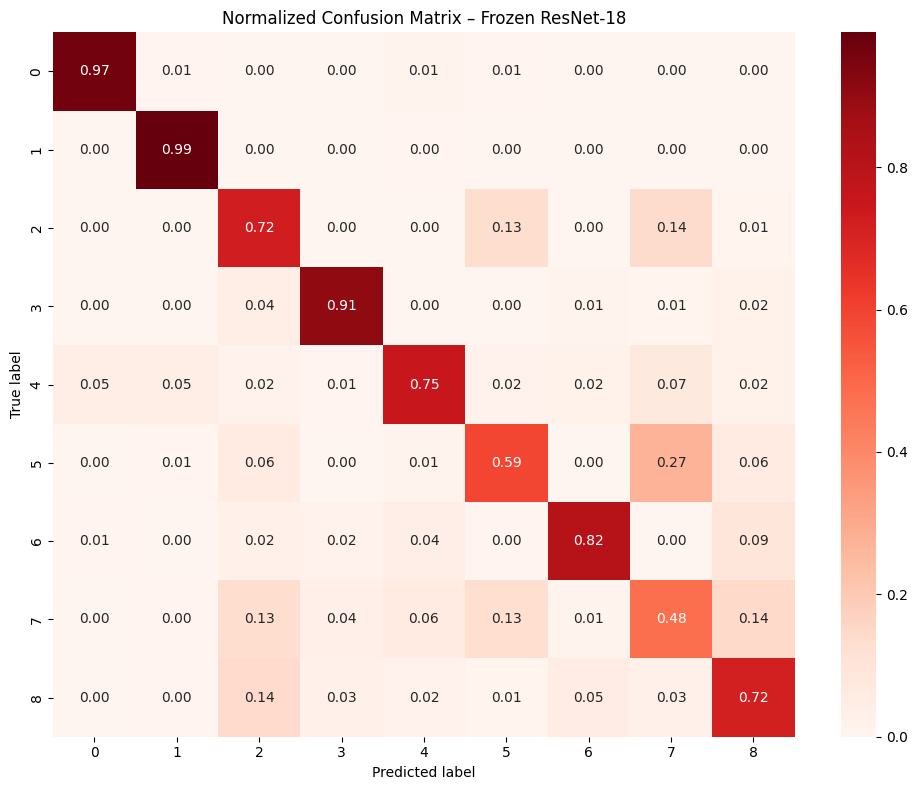

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Generate the raw confusion matrix
# cm = confusion_matrix(y_true, y_pred) # Already defined in your cell [16]

# 2. Normalize the matrix (rows sum to 1)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

# 3. Plot using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt=".2f", 
    cmap="Reds", 
    xticklabels=range(num_classes), 
    yticklabels=range(num_classes)
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Normalized Confusion Matrix – Frozen ResNet-18")
plt.tight_layout()
plt.show()

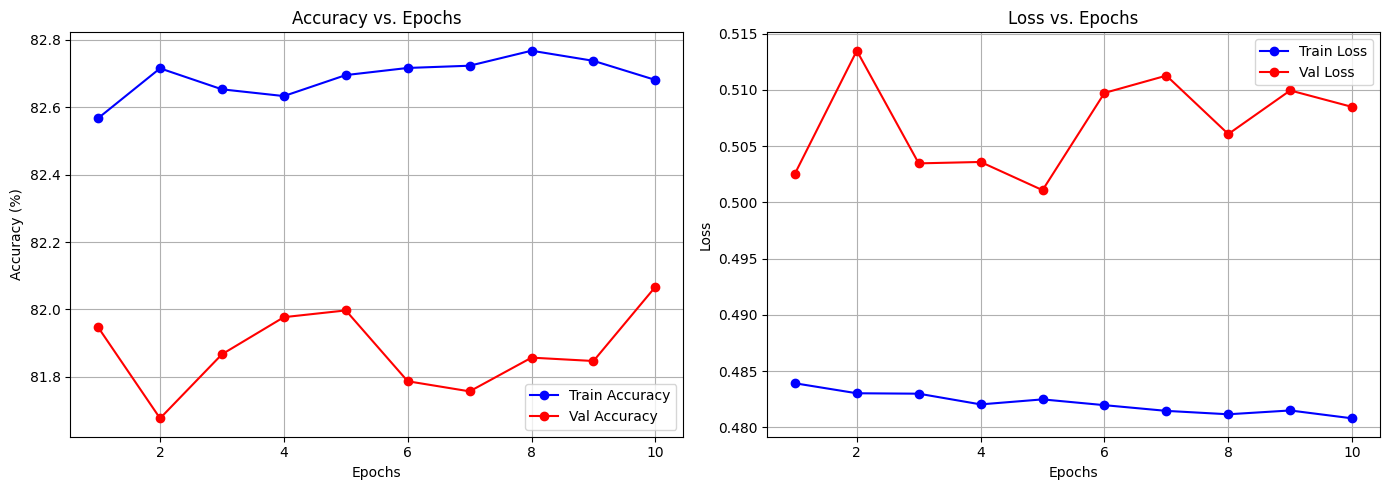

In [20]:
import matplotlib.pyplot as plt

# Create a range for the x-axis (1 to 10)
epoch_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epoch_range, train_accs, 'b-o', label='Train Accuracy')
plt.plot(epoch_range, val_accs, 'r-o', label='Val Accuracy')
plt.title('Accuracy vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epoch_range, train_losses, 'b-o', label='Train Loss')
plt.plot(epoch_range, val_losses, 'r-o', label='Val Loss')
plt.title('Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

# Assuming y_true and y_pred are already defined from your evaluation step
# PathMNIST classes (0-8)
target_names = [
    'adipose', 'background', 'debris', 'lymphoma', 'mucus', 
    'smooth muscle', 'normal colon', 'cancer-associated stroma', 'colorectal cancer'
]

# Generate the report
report = classification_report(
    y_true, 
    y_pred, 
    target_names=target_names,
    digits=4
)

print("### Classification Report: Frozen ResNet-18 ###")
print(report)

### Classification Report: Frozen ResNet-18 ###
                          precision    recall  f1-score   support

                 adipose     0.9579    0.9694    0.9636      1338
              background     0.9260    0.9894    0.9566       847
                  debris     0.4246    0.7227    0.5349       339
                lymphoma     0.8915    0.9069    0.8991       634
                   mucus     0.8814    0.7536    0.8125      1035
           smooth muscle     0.7088    0.5878    0.6427       592
            normal colon     0.8555    0.8151    0.8348       741
cancer-associated stroma     0.3811    0.4798    0.4248       421
       colorectal cancer     0.8123    0.7161    0.7612      1233

                accuracy                         0.8039      7180
               macro avg     0.7599    0.7712    0.7589      7180
            weighted avg     0.8221    0.8039    0.8090      7180



In [54]:
torch.save(
    {
        "classwise_accuracy": classwise_acc,
        "confusion_matrix_raw": cm,
        "confusion_matrix_normalized": cm_norm
    },
    "resnet18_test_metrics.pth"
)

print("✔ ResNet-18 test metrics saved")


✔ ResNet-18 test metrics saved


In [55]:
test_acc   # float, e.g. 88.01
torch.save(
    {
        "model": "Frozen ResNet-18 + Linear Probe",
        "dataset": "PathMNIST",
        "test_accuracy": test_acc
    },
    "resnet18_test_accuracy.pth"
)

print("✔ ResNet-18 test accuracy saved")


✔ ResNet-18 test accuracy saved
